# 15 · SHAP: why the detector calls a request an attack

SHAP splits every prediction into one contribution per feature: positive values push the request towards "attack", negative ones towards "normal", and together (plus a fixed starting value) they add up to the model's score. For tree models such as our XGBoost detector these values are computed exactly.

This notebook:
1. checks that the values from XGBoost (`pred_contribs=True`, used in `ml/explain.py`) are the same as the `shap` library's;
2. shows which features matter most overall (SHAP) next to XGBoost's own feature importance;
3. shows which features drive each attack type;
4. checks the sentences `ml/explain.py` gives for each flagged request: does the first reason point to the right attack family?

Data: development runs only (run3, run4 and camp7, both sites). The locked runs are not used. No request text is printed, only feature names and attack types.

In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from eval.match_labels import match
from ml.detector import MODEL_PATH, to_frame
from ml.explain import FEATURE_TEXT, KEYWORD_PARTS, contributions, reasons
from ml.train_defense import DEV_RUNS

D = ROOT / 'data'
NAMES = ['run3 JS', 'run4 JS', 'run4 DVWA', 'camp7 JS', 'camp7 DVWA']
PAYLOAD = ['sqli', 'xss', 'traversal', 'cmdi']
detector = joblib.load(MODEL_PATH)
frames, tables = [], []
for name, (log, labels) in zip(NAMES, DEV_RUNS):
    df, report = match(D / 'raw' / log, D / 'labels' / labels)
    frames.append(df.assign(run=name)[['run', 'label', 'attack_type']])
    tables.append(to_frame(df['method'], df['path'], df['body']))
    print(name, report)
R = pd.concat(frames, ignore_index=True)
X = pd.concat(tables, ignore_index=True)
R['pred'] = detector.predict(X)
values, names = contributions(detector, X)
S = pd.DataFrame(values[:, :-1], columns=names)
print(len(R), 'requests,', int(R['pred'].sum()), 'flagged')

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run3 JS {'log_lines': 4397, 'labels': 4397, 'matched': 4397, 'unmatched_log_lines': 0, 'unmatched_labels': 0}


run4 JS {'log_lines': 4296, 'labels': 4296, 'matched': 4296, 'unmatched_log_lines': 0, 'unmatched_labels': 0}


run4 DVWA {'log_lines': 3586, 'labels': 3567, 'matched': 3567, 'unmatched_log_lines': 19, 'unmatched_labels': 0}


camp7 JS {'log_lines': 6372, 'labels': 6372, 'matched': 6372, 'unmatched_log_lines': 0, 'unmatched_labels': 0}


camp7 DVWA {'log_lines': 6456, 'labels': 6387, 'matched': 6387, 'unmatched_log_lines': 69, 'unmatched_labels': 0}


25019 requests, 3697 flagged


## 1. Same numbers as the shap library

In [2]:
sample = np.random.RandomState(0).choice(len(X), 2000, replace=False)
Xt = detector.named_steps['features'].transform(X.iloc[sample])
lib = shap.TreeExplainer(detector.named_steps['model']).shap_values(Xt)
print('largest difference:', float(np.abs(lib - values[sample, :-1]).max()))
proba = 1 / (1 + np.exp(-values.sum(axis=1)))
print('contributions add up to the probability:', np.allclose(proba, detector.predict_proba(X)[:, 1], atol=1e-4))

largest difference: 0.0


contributions add up to the probability: True


## 2. Which features matter most

Mean absolute SHAP value per feature over all dev requests, next to XGBoost's own importance (total gain). SHAP says how much each feature moved the actual decisions; gain says how much it helped while the trees were built.

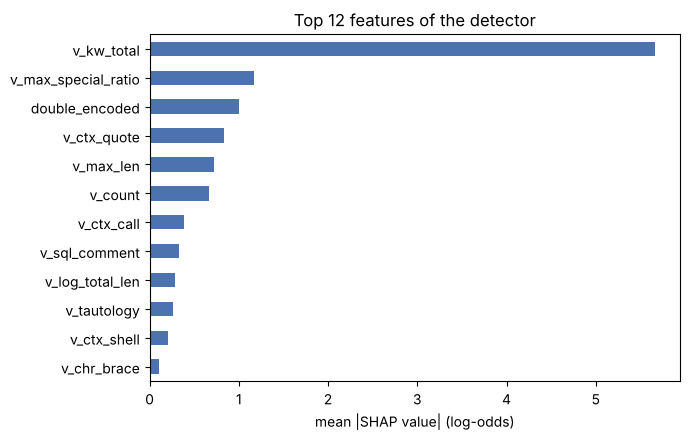

,mean |SHAP|,XGBoost gain share,meaning
v_kw_total,5.661,0.734,many attack keywords in total
v_max_special_ratio,1.167,0.001,a value made mostly of special characters
double_encoded,0.997,0.167,double URL encoding (%25..)
v_ctx_quote,0.829,0.034,a quote next to SQL syntax
v_max_len,0.726,0.002,a very long value
v_count,0.664,0.001,number of values the user sent
v_ctx_call,0.388,0.013,a function call in a value
v_sql_comment,0.327,0.003,an SQL comment (-- or /*)
v_log_total_len,0.280,0.000,a lot of user input in total
v_tautology,0.261,0.007,an always-true condition (like OR 1=1)


In [3]:
gain = detector.named_steps['model'].get_booster().get_score(importance_type='total_gain')
gain = {names[int(k[1:])] if k.startswith('f') and k[1:].isdigit() else k: v for k, v in gain.items()}
imp = pd.DataFrame({'mean |SHAP|': S.abs().mean(),
                    'XGBoost gain share': pd.Series(gain).reindex(names).fillna(0) / sum(gain.values())})
imp['meaning'] = [FEATURE_TEXT[n] for n in imp.index]
imp = imp.sort_values('mean |SHAP|', ascending=False).round(3)
top = imp.head(12)
ax = top['mean |SHAP|'][::-1].plot.barh(figsize=(7, 4.5), color='#4C72B0')
ax.set_xlabel('mean |SHAP value| (log-odds)'); ax.set_title('Top 12 features of the detector')
plt.tight_layout(); plt.show()
imp.head(15)

## 3. What drives each attack type

Mean SHAP value of each feature over the flagged attacks of one type (top 4 per type).

In [4]:
rows = []
for t in PAYLOAD:
    m = ((R['attack_type'] == t) & (R['pred'] == 1)).values
    mean = S[m].mean().sort_values(ascending=False).head(4)
    rows.append({'type': t, 'flagged': int(m.sum()),
                 **{f'#{k + 1}': f'{n} ({v:.2f})' for k, (n, v) in enumerate(mean.items())}})
pd.DataFrame(rows).set_index('type')

,flagged,#1,#2,#3,#4
type,,,,,
sqli,941,v_kw_total (4.22),v_ctx_quote (3.13),v_sql_comment (1.73),v_tautology (0.94)
xss,749,v_kw_total (5.45),v_ctx_call (2.98),v_count (1.45),v_max_special_ratio (0.85)
traversal,586,v_kw_total (6.95),double_encoded (5.06),v_count (0.82),v_kw_cmd (0.16)
cmdi,523,v_kw_total (7.51),v_ctx_shell (1.13),double_encoded (1.12),v_count (1.06)


## 4. Are the sentences right?

`reasons()` names up to three features per flagged request (only features present in the request; the keyword total is handed to the families that are present). Each feature belongs to one attack family; we check whether the **first** reason belongs to the true family of the attack.

In [5]:
FAMILY = {'sqli': ['v_ctx_quote', 'v_sql_comment', 'v_kw_sql', 'v_tautology'],
          'xss': ['v_ctx_tag', 'v_ctx_attr_break', 'v_kw_xss', 'p_kw_xss'],
          'traversal': ['v_kw_trav', 'p_kw_trav', 'double_encoded', 'null_byte'],
          'cmdi': ['v_ctx_shell', 'v_kw_cmd']}
family_of = {FEATURE_TEXT[f]: fam for fam, fs in FAMILY.items() for f in fs}
flagged = R.index[(R['pred'] == 1) & R['attack_type'].isin(PAYLOAD)]
why = reasons(detector, X.loc[flagged])
check = R.loc[flagged, ['attack_type']].copy()
check['first reason'] = [w[0] if w else '' for w in why]
check['family of first reason'] = check['first reason'].map(family_of).fillna('other')
check['match'] = check['family of first reason'] == check['attack_type']
check['any reason matches'] = [any(family_of.get(r) == t for r in w) for w, t in zip(why, check['attack_type'])]
print('flagged payload attacks:', len(check), '| with no reason:', int((check['first reason'] == '').sum()))
check.groupby('attack_type')[['match', 'any reason matches']].mean().round(3)

flagged payload attacks: 2799 | with no reason: 0


,match,any reason matches
attack_type,,
cmdi,0.824,0.960
sqli,0.961,1.000
traversal,1.000,1.000
xss,0.877,0.932


In [6]:
pd.crosstab(check['attack_type'], check['family of first reason'])

family of first reason,cmdi,sqli,traversal,xss
attack_type,,,,
cmdi,431,28,64,0
sqli,25,904,12,0
traversal,0,0,586,0
xss,0,74,18,657


In [7]:
# Normal requests the detector flagged get reasons too (there are none in these runs):
print('false alarms:', int(((R['pred'] == 1) & (R['label'] == 'normal')).sum()))
# Most common sentences per type
check.groupby('attack_type')['first reason'].agg(lambda s: s.value_counts().head(3).to_dict())

false alarms: 0


attack_type
cmdi         {'an OS command after a separator': 428, 'doub...
sqli         {'SQL keywords': 821, 'a quote next to SQL syn...
traversal    {'path traversal in the URL path': 287, 'path ...
xss          {'script / event-handler words': 657, 'SQL key...
Name: first reason, dtype: object

## Conclusion

- `ml/explain.py` gives exactly the shap library's values (largest difference 0.0), without needing the shap library in the backend.
- The detector leans most on the count of attack keywords, then on code-like characters (special characters, double encoding, quotes next to SQL syntax). Size features (how many values, how long) matter less.
- The first sentence names the right attack family for 100% of traversal, 96% of SQL injection, 88% of XSS and 82% of command injection; one of the three sentences does for 93-100%. When the first one does not, it still tells the truth about the model: it names the feature the model leaned on (for example a traversal mark inside a command injection that reads `/etc/hosts`, or SQL words inside an XSS value).
- The sentences are only an explanation: they never change a decision.
- Use in the system: the investigation page shows `reasons()` next to every flagged request.